In [ ]:
# GAN image generations

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
from keras import layers, models
from keras.datasets import mnist

DIGIT = 0      # which digit to learn
NOISE = 100    # size of random input
STEPS = 3000   # training steps
BATCH = 64     #images used in each round
 
np.random.seed(0)

In [5]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
 
def prep(x, y):
    x = x[y == DIGIT].reshape(-1, 784)
    return x / 255
 
x_train, x_test = prep(x_train, y_train), prep(x_test, y_test)
print(x_train.shape, x_test.shape)

(5923, 784) (980, 784)


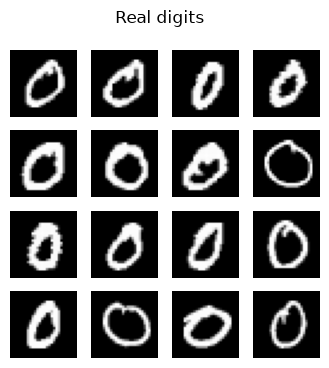

In [6]:
def show(imgs, title=""):
    fig, axes = plt.subplots(4, 4, figsize=(4, 4))
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img.reshape(28, 28), cmap="gray"); ax.axis("off")
    fig.suptitle(title); plt.show()
 
show(x_train[:16], "Real digits")

In [7]:
generator = models.Sequential([
    layers.Input((NOISE,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid"),
])
 
discriminator = models.Sequential([
    layers.Input((784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

discriminator.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
 
# Combined model: a frozen copy of the discriminator, so only the generator learns here
frozen_d = models.clone_model(discriminator)
frozen_d.trainable = False
gan = models.Sequential([generator, frozen_d])
gan.compile(loss="binary_crossentropy", optimizer="adam")

I0000 00:00:1794876833.636294     953 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1402 MB memory:  -> device: 0, name: NVIDIA GeForce MX350, pci bus id: 0000:01:00.0, compute capability: 6.1


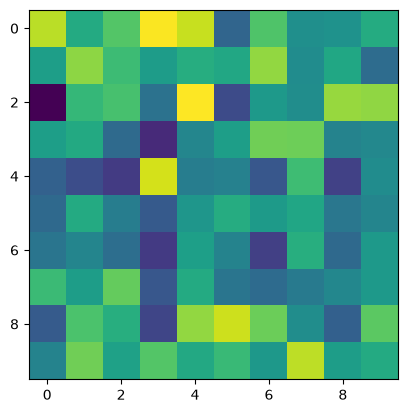

In [8]:
test_in_1  = np.random.randn(1,100)
test_in_2 = test_in_1.reshape(10,10)
plt.imshow(test_in_2)

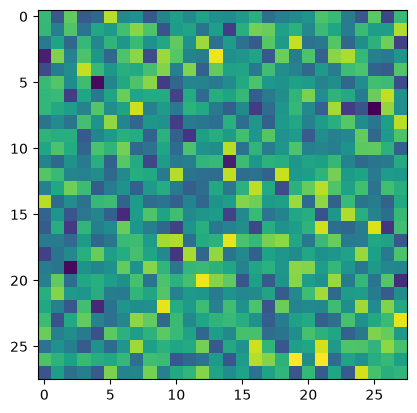

In [10]:
img_data = generator.predict(test_in_1, verbose=0)
img_data = img_data.reshape(28,28)
plt.imshow(img_data)

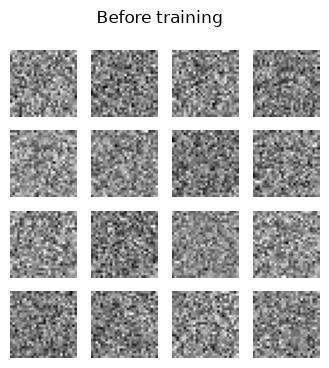

In [11]:
show(generator.predict(np.random.randn(16, NOISE), verbose=0), "Before training")

Step 1000: d_loss = 0.121, g_loss = 4.227


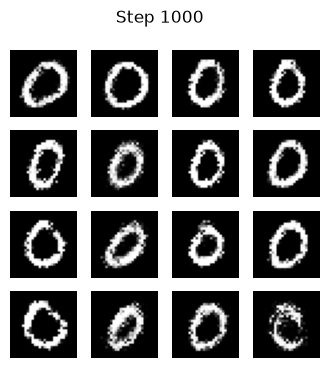

Step 2000: d_loss = 0.256, g_loss = 3.377


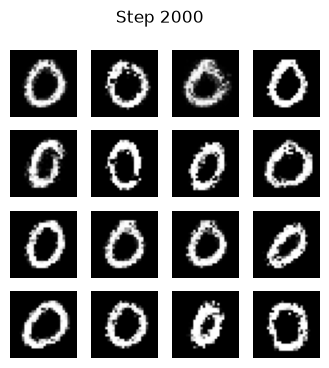

Step 3000: d_loss = 0.330, g_loss = 2.358


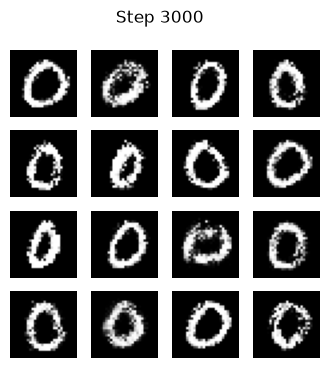

In [16]:
os.makedirs("checkpoints", exist_ok=True)
 
for step in range(1, STEPS + 1):
    real = x_train[np.random.randint(0, len(x_train), BATCH)]
    fake = generator.predict(np.random.randn(BATCH, NOISE), verbose=0)
 
    d_real = discriminator.train_on_batch(real, np.ones(BATCH))[0]
    d_fake = discriminator.train_on_batch(fake, np.zeros(BATCH))[0]
    
    frozen_d.set_weights(discriminator.get_weights())   # copy latest discriminator
    g_loss = gan.train_on_batch(np.random.randn(BATCH, NOISE), np.ones(BATCH))

    if step % 1000 == 0:
        d_loss = (d_real + d_fake) / 2
        print(f"Step {step}: d_loss = {d_loss:.3f}, g_loss = {g_loss:.3f}")
        show(generator.predict(np.random.randn(16, NOISE), verbose=0), f"Step {step}")
        generator.save(f"checkpoints/gen_{step}.keras")   # keep this version

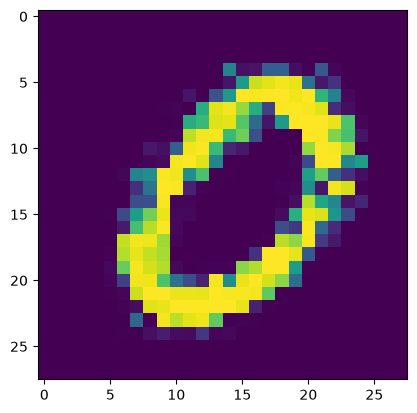

In [19]:
noise = np.random.randn(1,NOISE)
img_data = generator.predict(noise, verbose=0)
img_data = img_data.reshape(28,28)
plt.imshow(img_data)